# Task 13: IVCAN Cable Inspection


**Student edition: Digital Image Processing and Deep Learning**

Implement cable and stripe segmentation for the IVCAN/Prysmian dataset. The notebook provides data loading, ground-truth masks, fixed five-fold splits, metrics, contract validation, and the final evaluator.

- Implement the four functions marked with TODOs: segmenta_cabo, segmenta_listra, separar_amostras_fold, and resumir_cinco_folds. Complete the provided deterministic tests before running the full five-fold evaluation.
- You may create helper functions, but do not change the function signatures, `metricas_segmentacao`, the folds, or the evaluator.
- Tune parameters only with each fold's training samples, record them in `parametros_por_fold`, and freeze them before the test fold.
- Inputs are **RGB**. Use explicit OpenCV RGB conversions such as `cv2.COLOR_RGB2HSV` or `cv2.COLOR_RGB2LAB`.
- Never access IDs, reference masks, ground truth, or external labels inside segmentation functions. `segmenta_listra` receives the predicted cable mask, never the real one.


## 1. Install and import libraries

In [1]:
%pip install -q gdown opencv-python matplotlib pandas pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
# Deixa os gráficos aparecerem direto no notebook, inclusive quando ele é executado de forma automática.

import copy
import os
import zipfile
from pathlib import Path

import cv2

try:
    import gdown
except ImportError as error:
    raise ImportError(
        "The gdown package is required to download the dataset. "
        "Run '%pip install gdown' in this notebook's kernel."
    ) from error
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

plt.rcParams.update(
    {"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False}
)

## 2. Download and validate the public dataset

In [3]:
# Public ZIP file containing the complete IVCAN dataset.
ZIP_ID = "1q0OG-pHmEKcgAML49jlaZTmn0suO1p2j"

# Usamos o diretório do notebook atual por padrão.
# Caso precise, é só sobrescrever a variável de ambiente IVCAN_DATA_ROOT
# com o caminho que 'cê quiser pro diretório de dados.
DATA_ROOT = Path(
    os.environ.get("IVCAN_DATA_ROOT", str(Path.cwd()))
).expanduser()
ZIP_PATH = DATA_ROOT / "IVCAN-Dataset.zip"
EXTRACT_DIR = DATA_ROOT / "ivcan_zip_extracted"
DATASET_DIR = EXTRACT_DIR / "IVCAN-Dataset"
OUTPUT_DIR = DATA_ROOT / "ivcan_results"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Download once per local or hosted notebook session.
if not ZIP_PATH.is_file():
    result = gdown.download(
        id=ZIP_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )
    if not result:
        raise RuntimeError("Failed to download the public IVCAN ZIP.")

# Check whether the dataset has already been extracted completely.
def dataset_is_complete():
    if not all(
        (DATASET_DIR / name).exists()
        for name in ("dataset.csv", "Images", "Masks")
    ):
        return False

    images = DATASET_DIR / "Images"
    masks = DATASET_DIR / "Masks"

    return (
        sum(p.is_dir() for p in images.iterdir()) == 80
        and sum(p.is_dir() for p in masks.iterdir()) == 80
        and len(list(images.rglob("*.jpg"))) == 320
        and len(list(masks.rglob("*.jpg"))) == 552
    )

# Extract if needed.
if not dataset_is_complete():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        if archive.testzip() is not None:
            raise RuntimeError("The downloaded ZIP is corrupted.")
        archive.extractall(EXTRACT_DIR)

if not dataset_is_complete():
    raise RuntimeError(
        "Incomplete IVCAN dataset after extraction."
    )

# Preserve the original notebook interface.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pasta = str(DATASET_DIR)
resultados = OUTPUT_DIR

print("Dataset validated successfully!")
print("Dataset:", DATASET_DIR)
print("Images: 320")
print("Masks: 552")
print("Results:", OUTPUT_DIR)


Dataset validated successfully!
Dataset: c:\Users\Eduardo\Documents\UFAL\Matérias\cc-dl\tasks\task-13-ivcan-cable-inspection\ivcan_zip_extracted\IVCAN-Dataset
Images: 320
Masks: 552
Results: c:\Users\Eduardo\Documents\UFAL\Matérias\cc-dl\tasks\task-13-ivcan-cable-inspection\ivcan_results


## 3. Read dataset metadata

In [4]:
# Dataset path was validated in the configuration cell.
caminho_csv = os.path.join(pasta, "dataset.csv")

# utf-8-sig trata o marcador BOM presente no arquivo.
dados = pd.read_csv(caminho_csv, encoding="utf-8-sig", na_values=["-"])

# Limpa os nomes das colunas e corrige o nome da cor da listra.
dados.columns = dados.columns.str.strip()
dados = dados.rename(columns={"Cor lista": "Cor listra"})

# Limpa os IDs e define essa coluna como índice.
dados["ID"] = dados["ID"].str.strip().str.upper()
dados = dados.set_index("ID", verify_integrity=True)


def consultar_id(dados, id_amostra):
    """
    Aceita, por exemplo: 1, "001", "ID001" ou "ID003_2".
    Imprime todas as informações e retorna uma Series do pandas.
    """
    texto = str(id_amostra).strip().upper().removeprefix("ID")
    numero, separador, experimento = texto.partition("_")
    id_normalizado = f"ID{int(numero):03d}"

    if separador:
        id_normalizado += f"_{int(experimento)}"

    if id_normalizado not in dados.index:
        raise KeyError(f"O ID {id_normalizado} não está presente no CSV.")

    informacoes = dados.loc[id_normalizado]

    print(f"\nAmostra: {id_normalizado}")
    print("-" * 55)

    for campo, valor in informacoes.items():
        valor_exibido = "Não informado / não se aplica" if pd.isna(valor) else valor
        print(f"{campo}: {valor_exibido}")

    return informacoes

C:\Users\Eduardo\AppData\Local\Temp\ipykernel_26064\3679357626.py:13: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  dados = dados.set_index("ID", verify_integrity=True)


In [5]:
ID = "ID001"
print(dados.loc[ID])

Cor                            Marrom
Cor listra                     Branco
Diametro                        3.024
Espessura L1                    1.086
Espessura L2                    1.212
Comprimento do perimetro     9.500168
L1 %                        11.431377
L2 %                        12.757669
Cor Conforme                 Conforme
Listra Conforme              Conforme
Name: ID001, dtype: object


## 4. Inspect images and masks

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def carregar_e_plotar_amostra(pasta_dataset, id_amostra, experimento=1):
    """
    id_amostra: inteiro ou string, como 1, "001" ou "ID001".
    experimento: 1 ou 2.

    Retorna:
        imagens:       array RGB com as quatro imagens.
        mascaras_cabo: array com as quatro máscaras binárias do cabo.
        mascaras_listra: array com as quatro máscaras binárias da listra.
        fig, axes: objetos do Matplotlib.
    """
    # Normaliza o ID.
    numero = int(str(id_amostra).strip().upper().removeprefix("ID"))

    if not 1 <= numero <= 40:
        raise ValueError("O ID deve estar entre 001 e 040.")

    if experimento not in (1, 2):
        raise ValueError("O experimento deve ser 1 ou 2.")

    amostra = f"ID{numero:03d}_{experimento}"
    pasta_dataset = Path(pasta_dataset)

    pasta_imagens = pasta_dataset / "Images" / amostra
    pasta_mascaras = pasta_dataset / "Masks" / amostra

    def listar_arquivos(pasta):
        if not pasta.is_dir():
            raise FileNotFoundError(f"Pasta não encontrada: {pasta}")

        # Permite tanto CAMERA_0.jpg quanto Camera_0.jpg.
        return {
            arquivo.name.lower(): arquivo
            for arquivo in pasta.iterdir()
            if arquivo.is_file()
        }

    arquivos_imagens = listar_arquivos(pasta_imagens)
    arquivos_mascaras = listar_arquivos(pasta_mascaras)

    def ler_imagem(arquivos, nome, pasta, mascara=False):
        caminho = arquivos.get(nome.lower())

        if caminho is None:
            raise FileNotFoundError(f"Arquivo não encontrado: {pasta / nome}")

        modo = cv2.IMREAD_GRAYSCALE if mascara else cv2.IMREAD_COLOR
        # np.fromfile + imdecode supports Windows paths with non-ASCII characters.
        imagem = cv2.imdecode(np.fromfile(str(caminho), dtype=np.uint8), modo)

        if imagem is None:
            raise RuntimeError(f"Não foi possível ler: {caminho}")

        if mascara:
            # Binariza para eliminar pequenas variações causadas pelo JPEG.
            return np.where(imagem > 127, 255, 0).astype(np.uint8)

        return cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    imagens = []
    mascaras_cabo = []
    mascaras_listra = []

    for camera in range(4):
        imagem = ler_imagem(arquivos_imagens, f"CAMERA_{camera}.jpg", pasta_imagens)
        cabo = ler_imagem(
            arquivos_mascaras,
            f"CAMERA_{camera}_cable.jpg",
            pasta_mascaras,
            mascara=True,
        )

        nome_listra = f"CAMERA_{camera}_stripe.jpg"

        if nome_listra.lower() in arquivos_mascaras:
            listra = ler_imagem(
                arquivos_mascaras, nome_listra, pasta_mascaras, mascara=True
            )
        else:
            # Arquivo ausente representa um cabo sem listra.
            listra = np.zeros_like(cabo)

        if imagem.shape[:2] != cabo.shape or imagem.shape[:2] != listra.shape:
            raise ValueError(
                f"Câmera {camera}: imagem e máscaras possuem "
                f"dimensões diferentes: imagem={imagem.shape[:2]}, "
                f"cabo={cabo.shape}, listra={listra.shape}."
            )

        imagens.append(imagem)
        mascaras_cabo.append(cabo)
        mascaras_listra.append(listra)

    # Cada posição axes[linha, coluna] corresponde a um subplot.
    fig, axes = plt.subplots(4, 4, figsize=(18, 16))

    cor_cabo = (0, 255, 0)  # Verde em RGB.
    cor_listra = (255, 0, 0)  # Vermelho em RGB.

    for camera in range(4):
        imagem = imagens[camera]
        cabo = mascaras_cabo[camera]
        listra = mascaras_listra[camera]

        # Linha 1: imagens originais.
        axes[0, camera].imshow(imagem)
        axes[0, camera].set_title(f"Câmera {camera}", fontsize=13)

        # Linha 2: máscaras do cabo.
        axes[1, camera].imshow(cabo, cmap="gray", vmin=0, vmax=255)

        # Linha 3: máscaras da listra.
        axes[2, camera].imshow(listra, cmap="gray", vmin=0, vmax=255)

        # Linha 4: originais com contornos.
        sobreposicao = imagem.copy()

        for mascara, cor in ((cabo, cor_cabo), (listra, cor_listra)):
            contornos, _ = cv2.findContours(
                mascara.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            cv2.drawContours(
                sobreposicao, contornos, contourIdx=-1, color=cor, thickness=2
            )

        axes[3, camera].imshow(sobreposicao)

    nomes_linhas = [
        "Imagem original",
        "Máscara do cabo",
        "Máscara da listra",
        "Contornos",
    ]

    for linha in range(4):
        axes[linha, 0].set_ylabel(nomes_linhas[linha], fontsize=13)

        for coluna in range(4):
            ax = axes[linha, coluna]
            ax.set_xticks([])
            ax.set_yticks([])

            for borda in ax.spines.values():
                borda.set_visible(False)

    fig.suptitle(f"Amostra {amostra}", fontsize=18)

    fig.legend(
        handles=[
            Line2D([0], [0], color="lime", lw=2, label="Cabo"),
            Line2D([0], [0], color="red", lw=2, label="Listra"),
        ],
        loc="lower center",
        ncol=2,
        frameon=False,
        fontsize=12,
    )

    fig.tight_layout(rect=[0, 0.04, 1, 0.96])
    plt.show()

    return imagens, mascaras_cabo, mascaras_listra, fig, axes

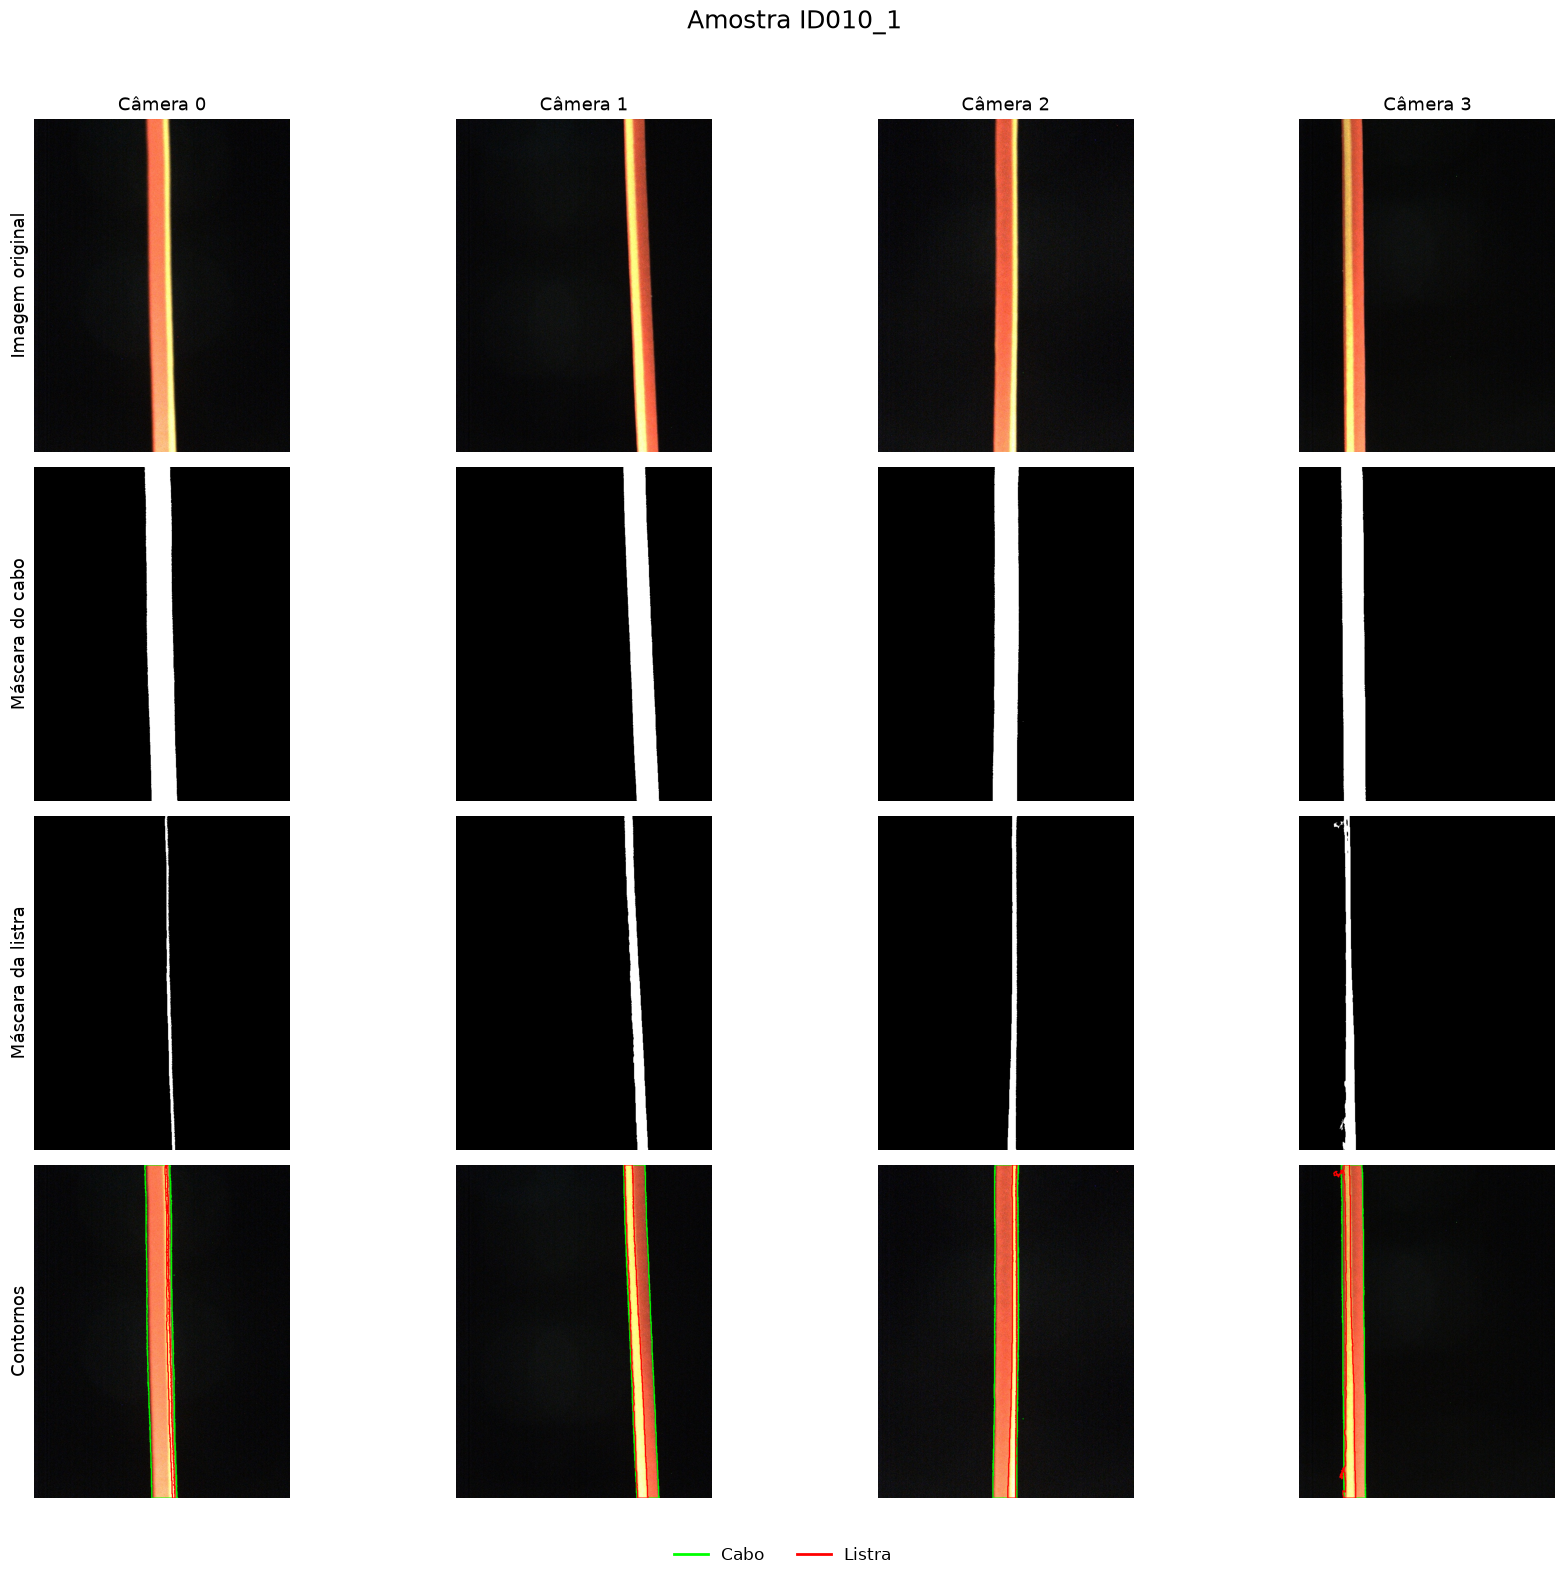

Cor                          Vermelho
Cor listra                    Amarelo
Diametro                        1.556
Espessura L1                    0.683
Espessura L2                     0.64
Comprimento do perimetro     4.888314
L1 %                        13.972097
L2 %                        13.092449
Cor Conforme                 Conforme
Listra Conforme              Conforme
Name: ID010, dtype: object


In [7]:
# The shared configuration cell already defines `pasta`.
ID = "ID010"
experimento = 1
carregar_e_plotar_amostra(pasta, ID, experimento)
print(dados.loc[ID])

## 5. Fixed five-fold split

In [8]:
# Índice da lista: número do ID menos 1.
# Valor: fold de teste daquele ID e experimento.

folds_exp1 = [
    1,
    3,
    2,
    3,
    4,
    5,
    2,
    5,
    4,
    2,  # ID001–ID010
    4,
    5,
    4,
    2,
    1,
    2,
    3,
    1,
    3,
    1,  # ID011–ID020
    1,
    2,
    3,
    4,
    3,
    4,
    1,
    2,
    5,
    5,  # ID021–ID030
    3,
    5,
    4,
    1,
    1,
    2,
    3,
    5,
    5,
    4,  # ID031–ID040
]

folds_exp2 = [
    1,
    3,
    2,
    3,
    4,
    5,
    2,
    5,
    4,
    2,  # ID001–ID010
    4,
    5,
    4,
    2,
    1,
    2,
    3,
    2,
    3,
    1,  # ID011–ID020
    1,
    2,
    3,
    4,
    3,
    4,
    1,
    3,
    5,
    5,  # ID021–ID030
    4,
    5,
    4,
    1,
    1,
    2,
    3,
    5,
    5,
    1,  # ID031–ID040
]

# Chaves correspondem aos nomes das pastas.
fold_por_amostra = {
    f"ID{numero:03d}_{experimento}": lista[numero - 1]
    for experimento, lista in [(1, folds_exp1), (2, folds_exp2)]
    for numero in range(1, 41)
}

# Verify the distribution of samples across the five fixed folds.
contagem_folds = pd.Series(fold_por_amostra).value_counts().sort_index()

print("Samples per fold:")
print(contagem_folds)

# Each fold must contain 16 ID-experiment pairs.
assert len(fold_por_amostra) == 80
assert (contagem_folds == 16).all()

print("Fixed fold assignments verified!")

Samples per fold:
1    16
2    16
3    16
4    16
5    16
Name: count, dtype: int64
Fixed fold assignments verified!


## 6. Provided metrics

In [9]:
def _validar_mascaras(ground_truth, predicao):
    """Valida e converte duas máscaras binárias 2D para booleano."""
    gt = np.asarray(ground_truth)
    pred = np.asarray(predicao)

    if gt.ndim != 2 or pred.ndim != 2:
        raise ValueError("As máscaras devem ser 2D: (altura, largura).")

    if gt.shape != pred.shape:
        raise ValueError(
            f"As máscaras devem ter o mesmo tamanho: "
            f"ground truth={gt.shape}, predição={pred.shape}."
        )

    if gt.size == 0:
        raise ValueError("As máscaras não podem estar vazias.")

    for nome, mascara in [("ground_truth", gt), ("predicao", pred)]:
        if not np.all(np.isin(mascara, [0, 1, 255])):
            raise ValueError(
                f"{nome} deve conter apenas valores binários "
                "(False/True, 0/1 ou 0/255). "
                "Para probabilidades, aplique um limiar antes."
            )

    return gt != 0, pred != 0


def metricas_segmentacao(ground_truth, predicao, zero_division=np.nan):
    """
    Calcula métricas de segmentação binária por pixel.

    Parâmetros
    ----------
    ground_truth, predicao : array-like, shape (H, W)
        Máscaras binárias. Zero = fundo; valor não zero = objeto.
    zero_division : float, default np.nan
        Valor retornado quando o denominador de uma métrica é zero.

    Retorna
    -------
    dict
        Contagens TP, TN, FP, FN e métricas na escala de 0 a 1.
    """
    gt, pred = _validar_mascaras(ground_truth, predicao)

    tp = int(np.count_nonzero(gt & pred))
    tn = int(np.count_nonzero(~gt & ~pred))
    fp = int(np.count_nonzero(~gt & pred))
    fn = int(np.count_nonzero(gt & ~pred))

    def dividir(numerador, denominador):
        if denominador == 0:
            return float(zero_division)
        return numerador / denominador

    recall = dividir(tp, tp + fn)

    return {
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "IoU": dividir(tp, tp + fp + fn),
        "TPR": recall,
        "FPR": dividir(fp, fp + tn),
        "Precisao": dividir(tp, tp + fp),
        "Revocacao": recall,
        "Acuracia": dividir(tp + tn, tp + tn + fp + fn),
        "Dice_F1": dividir(2 * tp, 2 * tp + fp + fn),
        "Especificidade": dividir(tn, tn + fp),
    }


def visualizar_erros_segmentacao(ground_truth, predicao):
    """
    Gera uma imagem RGB uint8 de diagnóstico, com shape (H, W, 3).

    Preto:    TN — fundo correto.
    Verde:    TP — objeto correto.
    Vermelho: FP — falso alarme.
    Amarelo:  FN — objeto não detectado.

    A saída está em RGB, pronta para matplotlib.pyplot.imshow.
    """
    gt, pred = _validar_mascaras(ground_truth, predicao)

    imagem = np.zeros((*gt.shape, 3), dtype=np.uint8)

    imagem[gt & pred] = (0, 200, 0)  # TP: verde
    imagem[~gt & pred] = (255, 0, 0)  # FP: vermelho
    imagem[gt & ~pred] = (255, 220, 0)  # FN: amarelo
    # TN permanece preto.

    return imagem

### 6.1 Example: using the provided metrics

TP             : 22663
TN             : 90359
FP             : 8967
FN             : 13011
IoU            : 0.5077
TPR            : 0.6353
FPR            : 0.0903
Precisao       : 0.7165
Revocacao      : 0.6353
Acuracia       : 0.8372
Dice_F1        : 0.6735
Especificidade : 0.9097


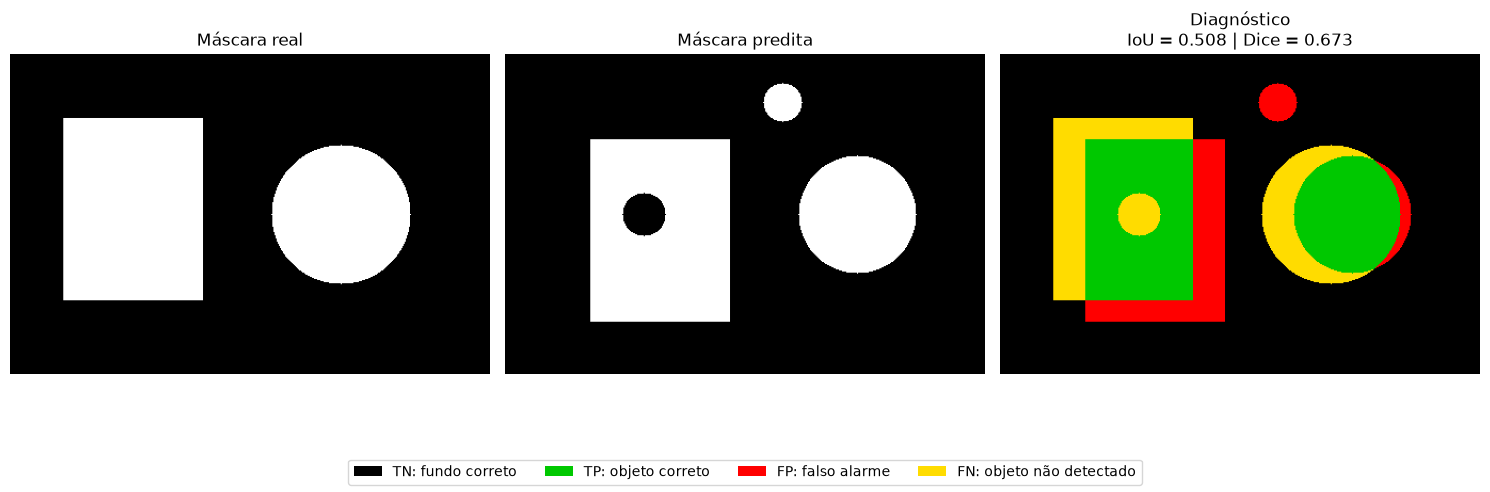

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# 1. Criar duas imagens inicialmente pretas.
altura, largura = 300, 450

mascara_real = np.zeros((altura, largura), dtype=np.uint8)
mascara_predita = np.zeros_like(mascara_real)

# 2. Ground truth: retângulo e círculo preenchidos.
# No OpenCV, coordenadas são fornecidas como (x, y).
cv2.rectangle(mascara_real, (50, 60), (180, 230), 255, thickness=-1)
cv2.circle(mascara_real, (310, 150), 65, 255, thickness=-1)

# 3. Predição com erros intencionais.

# Retângulo deslocado: gera falsos positivos e falsos negativos.
cv2.rectangle(mascara_predita, (80, 80), (210, 250), 255, thickness=-1)

# Círculo menor e deslocado: deixa parte do objeto sem detectar.
cv2.circle(mascara_predita, (330, 150), 55, 255, thickness=-1)

# Objeto inexistente no ground truth: falso positivo.
cv2.circle(mascara_predita, (260, 45), 18, 255, thickness=-1)

# Buraco dentro do retângulo: falsos negativos.
cv2.circle(mascara_predita, (130, 150), 20, 0, thickness=-1)

# 4. Calcular métricas com a função anterior.
metricas = metricas_segmentacao(mascara_real, mascara_predita)

for nome, valor in metricas.items():
    if nome in {"TP", "TN", "FP", "FN"}:
        print(f"{nome:15s}: {valor}")
    else:
        print(f"{nome:15s}: {valor:.4f}")

# 5. Gerar imagem de diagnóstico com a função anterior.
diagnostico = visualizar_erros_segmentacao(mascara_real, mascara_predita)

# 6. Exibir máscaras e diagnóstico.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(mascara_real, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Máscara real")

axes[1].imshow(mascara_predita, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Máscara predita")

axes[2].imshow(diagnostico)
axes[2].set_title(
    f"Diagnóstico\nIoU = {metricas['IoU']:.3f} | Dice = {metricas['Dice_F1']:.3f}"
)

for ax in axes:
    ax.axis("off")

fig.legend(
    handles=[
        Patch(facecolor="black", label="TN: fundo correto"),
        Patch(facecolor=(0, 200 / 255, 0), label="TP: objeto correto"),
        Patch(facecolor="red", label="FP: falso alarme"),
        Patch(facecolor=(1, 220 / 255, 0), label="FN: objeto não detectado"),
    ],
    loc="lower center",
    ncol=4,
)

plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

## 7. Student segmentation

Implement only the two functions below. Return binary 2D masks with the same height and width as the input image; accepted values are bool, `0/1`, or `0/255`. The cable mask includes the stripe region.

Do not consult reference masks, sample IDs, stripe labels, or ground truth inside these functions. `segmenta_listra` must use the **predicted** cable mask and may return an all-zero mask when no stripe is visible.### Estratégia usada

A solução é de **processamento digital de imagens**, sem treinar uma CNN.
Como o fundo é quase preto e o cabo aparece como uma faixa alongada, uma
abordagem por cor + geometria é barata, interpretável e roda bem em máquina
modesta. A ideia geral é:

1. **Cabo:** estimar a cor do fundo pelas bordas da imagem, medir a distância
   de cada pixel até essa cor, suavizar com mediana, fechar pequenas falhas e
   ficar com o maior componente conectado. No fim, preencho buracos internos
   para não perder listras escuras que ficam dentro do cabo.
2. **Listra:** erodir um pouco a máscara predita do cabo para fugir das bordas
   sombreadas, estimar a cor do corpo do cabo linha a linha e procurar pixels
   com diferença de cor (Lab e cromaticidade). Só ficam componentes compridos
   no sentido vertical; se nada comprido sobrar, a função devolve máscara
   vazia (caso de câmera em que a listra não aparece).

Os parâmetros foram congelados por fold usando somente as amostras de treino.
O fold de teste nunca participou da escolha.


In [11]:
def _maior_componente(mascara):
    """Mantém apenas a maior região conectada (o cabo ocupa uma faixa só)."""
    quantidade, rotulos, estatisticas, _ = cv2.connectedComponentsWithStats(
        mascara.astype(np.uint8), connectivity=8
    )

    if quantidade <= 1:
        return np.zeros_like(mascara, dtype=bool)

    # A coluna 4 de stats é a área de cada componente.
    indice_maior = 1 + int(np.argmax(estatisticas[1:, cv2.CC_STAT_AREA]))
    return rotulos == indice_maior


def _preencher_buracos(mascara):
    """Preenche buracos internos sem engolir o fundo que encosta na borda."""
    fundo = (~mascara).astype(np.uint8)
    quantidade, rotulos, _, _ = cv2.connectedComponentsWithStats(
        fundo, connectivity=4
    )

    if quantidade <= 1:
        return mascara

    # Componentes de fundo que aparecem na borda são fundo de verdade.
    borda = np.unique(
        np.concatenate(
            [rotulos[0], rotulos[-1], rotulos[:, 0], rotulos[:, -1]]
        )
    )
    regiao_de_fundo = np.isin(rotulos, borda)

    # O que não é cabo nem fundo externo é buraco: geralmente listra escura.
    buracos = (~mascara) & (~regiao_de_fundo)
    return mascara | buracos


def segmenta_cabo(imagem_rgb, parametros=None):
    """
    Segmenta o cabo automotivo em uma imagem RGB.

    Retorna uma máscara binária 2D com as mesmas
    dimensões espaciais da imagem original.

    O cabo deve incluir também a região da listra.
    """
    parametros = {} if parametros is None else parametros
    mascara_cabo = None

    ### START CODE HERE ###

    # Parâmetros padrão. Cada fold pode sobrescrever o que quiser.
    opcoes = {
        "limiar": 35.0,          # distância mínima até a cor do fundo
        "mediana": 3,            # suaviza ruído de JPEG/sensor
        "fechamento": 5,         # fecha pequenas falhas no contorno
        "margem_borda": 20,      # pixels da borda usados pra estimar o fundo
        "preencher": True,       # preenche buracos internos (ex.: listra escura)
    }
    opcoes.update(parametros)

    imagem = np.asarray(imagem_rgb)
    if imagem.dtype != np.uint8:
        imagem = np.clip(imagem, 0, 255).astype(np.uint8)
    if imagem.ndim == 2:
        imagem = cv2.cvtColor(imagem, cv2.COLOR_GRAY2RGB)

    altura, largura = imagem.shape[:2]
    margem = max(1, min(int(opcoes["margem_borda"]), altura // 2, largura // 2))

    # O fundo é quase preto e uniforme. A mediana das bordas dá uma cor
    # de referência sem depender de nenhum ID ou máscara gabarito.
    bordas = np.concatenate(
        [
            imagem[:margem].reshape(-1, 3),
            imagem[-margem:].reshape(-1, 3),
            imagem[:, :margem].reshape(-1, 3),
            imagem[:, -margem:].reshape(-1, 3),
        ],
        axis=0,
    )
    cor_fundo = np.median(bordas, axis=0)

    # Distância euclidiana em RGB: qualquer coisa muito diferente do fundo
    # vira candidata a cabo. Isso funciona até para cabos escuros/coloridos.
    distancia = np.sqrt(
        ((imagem.astype(np.float32) - cor_fundo) ** 2).sum(axis=2)
    )
    pontuacao = np.clip(distancia, 0, 255).astype(np.uint8)

    mediana = int(opcoes["mediana"])
    if mediana >= 3:
        if mediana % 2 == 0:
            mediana += 1
        pontuacao = cv2.medianBlur(pontuacao, mediana)

    mascara = (pontuacao > float(opcoes["limiar"])).astype(np.uint8)

    # Fechamento junta pedaços quebrados pelo reflexo/ruído.
    fechamento = int(opcoes["fechamento"])
    if fechamento >= 3:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (fechamento, fechamento)
        )
        mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel)

    # O cabo é o maior objeto claro da cena; descarto blobs soltos ao redor.
    mascara = _maior_componente(mascara)

    # Preencher buracos ajuda a incluir listras escuras dentro do cabo.
    if bool(opcoes["preencher"]):
        mascara = _preencher_buracos(mascara)

    mascara_cabo = mascara.astype(np.uint8) * 255

    ### END CODE HERE ###

    if mascara_cabo is None:
        raise NotImplementedError("Implemente segmenta_cabo.")

    return mascara_cabo


### Segment the stripe

Use the image and the **predicted** cable mask. The function must handle images without a visible stripe by returning an entirely black mask.

In [12]:
def _referencia_por_linha(imagem_lab, nucleo, passo_linhas=8):
    """Estima a cor do corpo do cabo linha a linha e interpola o resto."""
    altura = imagem_lab.shape[0]
    passo = max(1, int(passo_linhas))
    linhas = np.unique(np.append(np.arange(0, altura, passo), altura - 1))

    cor_global = np.median(imagem_lab[nucleo], axis=0)
    amostras = []

    # Em vez de calcular a mediana de todas as 808 linhas, faço isso
    # de 8 em 8 e interpolo. O resultado fica praticamente igual e roda rápido.
    for y in linhas:
        xs = np.flatnonzero(nucleo[y])
        if xs.size >= 5:
            amostras.append(np.median(imagem_lab[y, xs], axis=0))
        else:
            amostras.append(cor_global)

    amostras = np.asarray(amostras)
    referencia = np.empty_like(imagem_lab)
    eixo_y = np.arange(altura)

    for canal in range(3):
        referencia[..., canal] = np.interp(
            eixo_y, linhas, amostras[:, canal]
        )[:, None]

    return referencia


def segmenta_listra(imagem_rgb, mascara_cabo_predita, parametros=None):
    """
    Segmenta a listra do cabo usando a imagem RGB
    e a máscara predita do cabo.

    Retorna uma máscara binária 2D.
    """
    parametros = {} if parametros is None else parametros
    mascara_listra = None

    ### START CODE HERE ###

    opcoes = {
        "margem_borda": 2,       # erosão pra não pegar sombra da borda do cabo
        "limiar_croma": 25.0,    # diferença de cor (componentes a*, b* do Lab)
        "limiar_lab": 80.0,      # diferença total no Lab (pega listra branca/preta)
        "altura_min_frac": 0.5,  # fração mínima da altura pra aceitar o componente
        "passo_linhas": 8,       # amostragem da cor de referência por linha
        "area_min": 100,         # tira lasquinhas de ruído
    }
    opcoes.update(parametros)

    imagem = np.asarray(imagem_rgb)
    if imagem.dtype != np.uint8:
        imagem = np.clip(imagem, 0, 255).astype(np.uint8)
    if imagem.ndim == 2:
        imagem = cv2.cvtColor(imagem, cv2.COLOR_GRAY2RGB)

    cabo = np.asarray(mascara_cabo_predita) != 0
    if not cabo.any():
        # Sem cabo predito não existe listra possível.
        return np.zeros(imagem.shape[:2], dtype=np.uint8)

    margem = max(0, int(opcoes["margem_borda"]))
    if margem > 0:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (2 * margem + 1, 2 * margem + 1)
        )
        nucleo = cv2.erode(cabo.astype(np.uint8), kernel) > 0
    else:
        nucleo = cabo.copy()

    # Se o cabo for muito fino, a erosão pode acabar com tudo.
    if nucleo.sum() < 50:
        nucleo = cabo

    # A entrada é RGB, então a conversão precisa ser RGB2LAB mesmo.
    imagem_lab = cv2.cvtColor(imagem, cv2.COLOR_RGB2LAB).astype(np.float32)
    referencia = _referencia_por_linha(
        imagem_lab, nucleo, opcoes["passo_linhas"]
    )

    # Distância total no Lab e distância só de cromaticidade (a*, b*).
    # A cromaticidade pega troca de cor; a distância total pega listra
    # branca ou preta, que muda mais o brilho do que o matiz.
    distancia_lab = np.linalg.norm(imagem_lab - referencia, axis=2)
    distancia_croma = np.linalg.norm(
        imagem_lab[..., 1:] - referencia[..., 1:], axis=2
    )

    candidata = (
        nucleo
        & (
            (distancia_croma > float(opcoes["limiar_croma"]))
            | (distancia_lab > float(opcoes["limiar_lab"]))
        )
    ).astype(np.uint8)

    # A listra é comprida no sentido vertical. Componentes baixinhos são
    # reflexos, ruído de JPEG ou sobra da borda do cabo.
    quantidade, rotulos, estatisticas, _ = cv2.connectedComponentsWithStats(
        candidata, connectivity=8
    )

    saida = np.zeros_like(cabo, dtype=bool)
    if quantidade > 1:
        alturas = estatisticas[1:, cv2.CC_STAT_HEIGHT]
        areas = estatisticas[1:, cv2.CC_STAT_AREA]
        altura_minima = float(opcoes["altura_min_frac"]) * imagem.shape[0]

        validos = np.where(
            (alturas >= altura_minima) & (areas >= int(opcoes["area_min"]))
        )[0] + 1

        if validos.size > 0:
            saida = np.isin(rotulos, validos)

    # Se nada comprido sobrou, devolvo tudo preto: é o caso de câmera
    # em que a listra não está visível.
    mascara_listra = saida.astype(np.uint8) * 255

    ### END CODE HERE ###

    if mascara_listra is None:
        raise NotImplementedError("Implemente segmenta_listra.")

    return mascara_listra


## 8. Parameters and experimental protocol


O dicionário abaixo permite parâmetros diferentes por fold. As chaves internas
dependem da sua implementação: por exemplo, um limiar de intensidade ou o tamanho
de um elemento estruturante. Dicionários vazios usam os padrões que você definir.

Para o fold `k`, somente `fold != k` pode ser usado para escolher parâmetros.
`avaliar_cinco_folds` apenas avalia: não faz treinamento nem busca automaticamente.
Se houver uma etapa de ajuste, execute-a separadamente com as amostras de treino
retornadas por `separar_amostras_fold` e registre o resultado aqui.

As quatro câmeras de cada par ID–experimento permanecem no mesmo fold.
Nos IDs 018, 028, 031 e 040, os experimentos foram separados para manter exemplos
das cores exclusivas no treino. Nesses casos, a avaliação é entre experimentos
do mesmo cabo físico; registre essa limitação no relatório.


In [13]:
def separar_amostras_fold(fold_por_amostra, fold_teste):
    """
    Separa os nomes das amostras de treino e teste.

    O fold escolhido será utilizado exclusivamente
    para teste. Os outros quatro serão de treino.

    Retorna:
        treino: lista ordenada de amostras
        teste: lista ordenada de amostras
    """
    if fold_teste not in (1, 2, 3, 4, 5):
        raise ValueError("Fold inválido.")

    treino = None
    teste = None

    ### START CODE HERE ###

    treino = []
    teste = []

    # Percorro o dicionário uma vez só. Se o fold da amostra é o fold
    # separado pra teste, ela vai pra teste; senão, vai pra treino.
    for amostra, fold in fold_por_amostra.items():
        if fold == fold_teste:
            teste.append(amostra)
        else:
            treino.append(amostra)

    # Ordenar deixa o resultado determinístico e facilita comparar execuções.
    treino = sorted(treino)
    teste = sorted(teste)

    ### END CODE HERE ###

    if treino is None or teste is None:
        raise NotImplementedError("Implemente separar_amostras_fold.")

    return treino, teste


In [14]:
# Deterministic test: train/test fold separation.

folds_teste = {
    "ID001_1": 1,
    "ID002_1": 2,
    "ID003_1": 3,
    "ID004_1": 4,
    "ID005_1": 5,
}

treino_teste, teste_teste = separar_amostras_fold(folds_teste, 1)

assert teste_teste == ["ID001_1"]
assert treino_teste == [
    "ID002_1",
    "ID003_1",
    "ID004_1",
    "ID005_1",
]

print("Fold split test passed!")

Fold split test passed!


In [15]:
# Parâmetros congelados depois de um ajuste feito SÓ com o treino de cada fold.
# Foi uma busca pequena em grade: limite do cabo e limiares de cor da listra.
# Pra não pesar no computador, usei um subconjunto do treino (uma amostra a
# cada quatro) com as quatro câmeras. O fold de teste nunca entrou na escolha.
parametros_por_fold = {
    1: {
        "cabo": {
            "limiar": 35.0,
            "mediana": 3,
            "fechamento": 5,
            "margem_borda": 20,
            "preencher": True,
        },
        "listra": {
            "margem_borda": 2,
            "limiar_croma": 25.0,
            "limiar_lab": 80.0,
            "altura_min_frac": 0.5,
            "passo_linhas": 8,
            "area_min": 100,
        },
    },
    2: {
        "cabo": {
            "limiar": 38.0,
            "mediana": 3,
            "fechamento": 5,
            "margem_borda": 20,
            "preencher": True,
        },
        "listra": {
            "margem_borda": 2,
            "limiar_croma": 25.0,
            "limiar_lab": 80.0,
            "altura_min_frac": 0.5,
            "passo_linhas": 8,
            "area_min": 100,
        },
    },
    3: {
        "cabo": {
            "limiar": 35.0,
            "mediana": 3,
            "fechamento": 5,
            "margem_borda": 20,
            "preencher": True,
        },
        "listra": {
            "margem_borda": 2,
            "limiar_croma": 25.0,
            "limiar_lab": 100.0,
            "altura_min_frac": 0.5,
            "passo_linhas": 8,
            "area_min": 100,
        },
    },
    4: {
        "cabo": {
            "limiar": 35.0,
            "mediana": 3,
            "fechamento": 5,
            "margem_borda": 20,
            "preencher": True,
        },
        "listra": {
            "margem_borda": 2,
            "limiar_croma": 25.0,
            "limiar_lab": 80.0,
            "altura_min_frac": 0.6,
            "passo_linhas": 8,
            "area_min": 100,
        },
    },
    5: {
        "cabo": {
            "limiar": 38.0,
            "mediana": 3,
            "fechamento": 5,
            "margem_borda": 20,
            "preencher": True,
        },
        "listra": {
            "margem_borda": 2,
            "limiar_croma": 25.0,
            "limiar_lab": 80.0,
            "altura_min_frac": 0.6,
            "passo_linhas": 8,
            "area_min": 100,
        },
    },
}

# Exemplo: amostras de treino do fold 1.
fold_desenvolvimento = 1

treino_desenvolvimento, teste_desenvolvimento = separar_amostras_fold(
    fold_por_amostra,
    fold_desenvolvimento,
)

print("Pastas de treino:", treino_desenvolvimento)
print("Pastas de teste:", teste_desenvolvimento)
print("Parâmetros do fold 1:", parametros_por_fold[1])


Pastas de treino: ['ID002_1', 'ID002_2', 'ID003_1', 'ID003_2', 'ID004_1', 'ID004_2', 'ID005_1', 'ID005_2', 'ID006_1', 'ID006_2', 'ID007_1', 'ID007_2', 'ID008_1', 'ID008_2', 'ID009_1', 'ID009_2', 'ID010_1', 'ID010_2', 'ID011_1', 'ID011_2', 'ID012_1', 'ID012_2', 'ID013_1', 'ID013_2', 'ID014_1', 'ID014_2', 'ID016_1', 'ID016_2', 'ID017_1', 'ID017_2', 'ID018_2', 'ID019_1', 'ID019_2', 'ID022_1', 'ID022_2', 'ID023_1', 'ID023_2', 'ID024_1', 'ID024_2', 'ID025_1', 'ID025_2', 'ID026_1', 'ID026_2', 'ID028_1', 'ID028_2', 'ID029_1', 'ID029_2', 'ID030_1', 'ID030_2', 'ID031_1', 'ID031_2', 'ID032_1', 'ID032_2', 'ID033_1', 'ID033_2', 'ID036_1', 'ID036_2', 'ID037_1', 'ID037_2', 'ID038_1', 'ID038_2', 'ID039_1', 'ID039_2', 'ID040_1']
Pastas de teste: ['ID001_1', 'ID001_2', 'ID015_1', 'ID015_2', 'ID018_1', 'ID020_1', 'ID020_2', 'ID021_1', 'ID021_2', 'ID027_1', 'ID027_2', 'ID034_1', 'ID034_2', 'ID035_1', 'ID035_2', 'ID040_2']
Parâmetros do fold 1: {'cabo': {'limiar': 35.0, 'mediana': 3, 'fechamento': 5, 'mar

## 9. Provided evaluation loader


Este carregador não gera figuras durante a avaliação. Ele lê imagens em RGB e
binariza máscaras JPEG com limiar 127. Mantém a convenção já adotada no notebook:
arquivo de máscara de listra ausente representa ground truth vazio. Confirme que
essa ausência significa realmente cabo sem listra, e não anotação perdida.

Pasta/máscara do cabo ausente, JPEG truncado, dimensões incompatíveis e máscaras
uniformes incompatíveis com o cenário são erros de dados. O avaliador pode
interromper ou registrar e excluir esses casos, conforme a opção escolhida.
Ele não associa automaticamente `ID035_3` a `ID035_1` nem corrige anotações.


In [16]:
import re


class ErroDadosAvaliacao(ValueError):
    """Erro nos arquivos de entrada; não representa falha do algoritmo discente."""


def _localizar_arquivo(pasta_arquivos, radical, obrigatorio=True):
    pasta_arquivos = Path(pasta_arquivos)
    if not pasta_arquivos.is_dir():
        raise ErroDadosAvaliacao(f"Pasta não encontrada: {pasta_arquivos}")
    extensoes = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    encontrados = [
        p
        for p in pasta_arquivos.iterdir()
        if p.is_file()
        and p.stem.lower() == radical.lower()
        and p.suffix.lower() in extensoes
    ]
    if len(encontrados) > 1:
        raise ErroDadosAvaliacao(
            f"Mais de um arquivo corresponde a {pasta_arquivos / radical}."
        )
    if not encontrados:
        if obrigatorio:
            raise ErroDadosAvaliacao(
                f"Arquivo não encontrado: {pasta_arquivos / radical}"
            )
        return None
    return encontrados[0]


def _ler_arquivo_verificado(caminho, modo):
    try:
        # O OpenCV pode aceitar JPEG truncado; exige-se decodificação completa.
        with Image.open(caminho) as imagem_pil:
            imagem_pil.load()
    except (OSError, ValueError) as erro:
        raise ErroDadosAvaliacao(f"Arquivo inválido: {caminho}: {erro}") from erro
    # np.fromfile + imdecode supports Windows paths with non-ASCII characters.
    imagem = cv2.imdecode(np.fromfile(str(caminho), dtype=np.uint8), modo)
    if imagem is None:
        raise ErroDadosAvaliacao(f"Não foi possível decodificar: {caminho}")
    return imagem


def carregar_imagem_avaliacao(pasta_dataset, amostra, camera):
    """Lê uma imagem RGB e duas máscaras, sem gerar figuras.

    Preserva a convenção do notebook: máscara de listra ausente = GT vazio.
    Uma pasta de máscaras ausente ou uma máscara de cabo ausente é erro.
    """
    if re.fullmatch(r"ID\d{3}_[12]", amostra) is None:
        raise ValueError(f"Nome inválido de amostra: {amostra}")
    if not 1 <= int(amostra[2:5]) <= 40 or camera not in range(4):
        raise ValueError("Esperados IDs 001 a 040 e câmeras 0 a 3.")
    raiz = Path(pasta_dataset)
    p_img = raiz / "Images" / amostra
    p_mask = raiz / "Masks" / amostra
    imagem_path = _localizar_arquivo(p_img, f"CAMERA_{camera}")
    cabo_path = _localizar_arquivo(p_mask, f"CAMERA_{camera}_cable")
    listra_path = _localizar_arquivo(
        p_mask, f"CAMERA_{camera}_stripe", obrigatorio=False
    )

    imagem_bgr = _ler_arquivo_verificado(imagem_path, cv2.IMREAD_COLOR)
    cabo = _ler_arquivo_verificado(cabo_path, cv2.IMREAD_GRAYSCALE)
    cabo = np.where(cabo > 127, 255, 0).astype(np.uint8)
    if listra_path is None:
        listra = np.zeros_like(cabo)
    else:
        listra = _ler_arquivo_verificado(listra_path, cv2.IMREAD_GRAYSCALE)
        listra = np.where(listra > 127, 255, 0).astype(np.uint8)
    if imagem_bgr.shape[:2] != cabo.shape or listra.shape != cabo.shape:
        raise ErroDadosAvaliacao(
            f"{amostra}, câmera {camera}: dimensões incompatíveis."
        )
    if not cabo.any() or np.all(cabo != 0) or np.all(listra != 0):
        raise ErroDadosAvaliacao(
            f"{amostra}, câmera {camera}: máscara uniforme incompatível "
            "com cabo sobre fundo."
        )
    return cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB), cabo, listra


def _validar_predicao_discente(predicao, shape, nome_funcao):
    if predicao is None:
        raise NotImplementedError(
            f"{nome_funcao} retornou None. Preencha a região "
            "START CODE HERE / END CODE HERE."
        )
    predicao = np.asarray(predicao)
    # Reaproveita a validação binária do notebook, sem passar nenhum GT discente.
    _, binaria = _validar_mascaras(np.zeros(shape, dtype=np.uint8), predicao)
    return binaria.astype(np.uint8) * 255

## 10. Contract test and a training-image visualization


Execute após implementar as duas funções. O teste verifica dimensões, valores
binários e preservação das entradas; ele não exige uma segmentação perfeita.
Uma função ainda não implementada gera `NotImplementedError`, evitando resultados
artificiais para máscaras vazias usadas como substitutas da implementação.


In [17]:
def testar_contrato_segmentacao(
    imagem_rgb, parametros_cabo=None, parametros_listra=None
):
    """Testa a interface e a preservação das entradas; não mede a qualidade."""
    imagem_original = imagem_rgb.copy()
    pred_cabo = _validar_predicao_discente(
        segmenta_cabo(imagem_rgb, copy.deepcopy(parametros_cabo)),
        imagem_rgb.shape[:2],
        "segmenta_cabo",
    )
    np.testing.assert_array_equal(imagem_rgb, imagem_original)
    cabo_original = pred_cabo.copy()
    pred_listra = _validar_predicao_discente(
        segmenta_listra(imagem_rgb, pred_cabo, copy.deepcopy(parametros_listra)),
        imagem_rgb.shape[:2],
        "segmenta_listra",
    )
    np.testing.assert_array_equal(imagem_rgb, imagem_original)
    np.testing.assert_array_equal(pred_cabo, cabo_original)
    print(
        "Contrato verificado: máscaras binárias do tamanho correto; "
        "entradas preservadas."
    )
    return pred_cabo, pred_listra

Contrato verificado: máscaras binárias do tamanho correto; entradas preservadas.


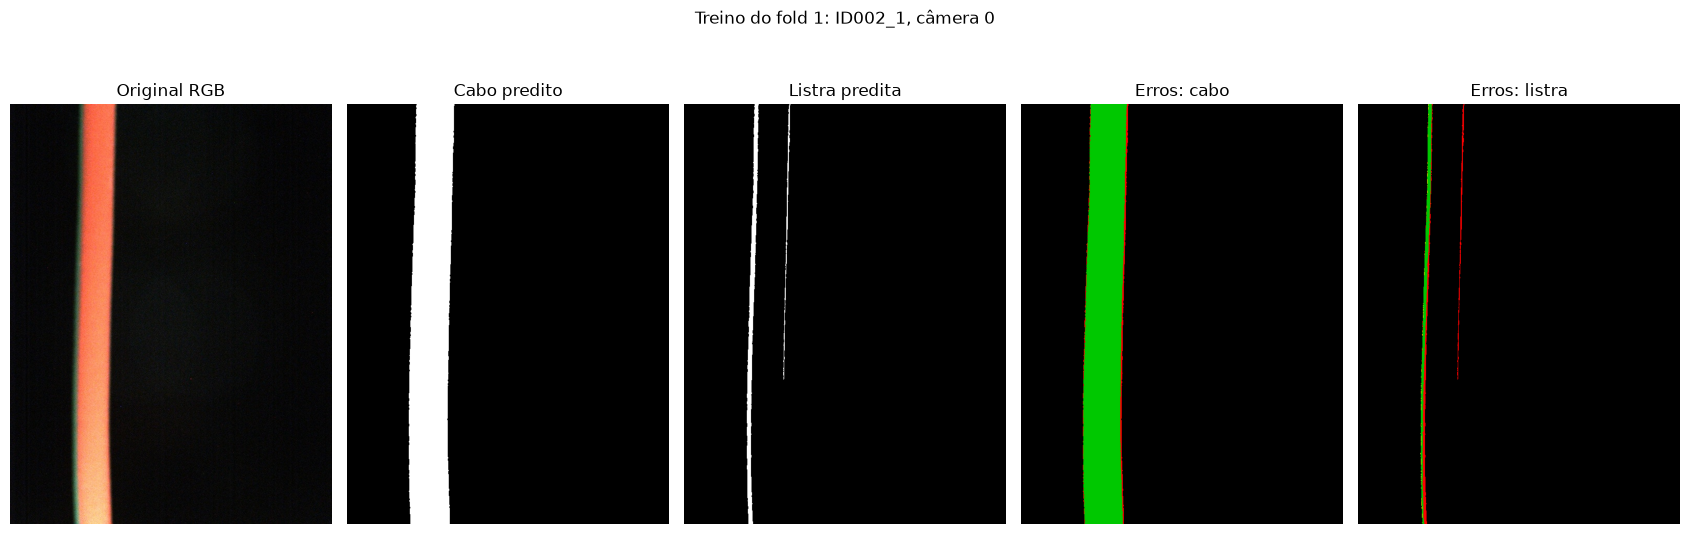

In [18]:
amostra_exemplo = treino_desenvolvimento[0]
camera_exemplo = 0
imagem_exemplo, gt_cabo_exemplo, gt_listra_exemplo = carregar_imagem_avaliacao(
    pasta, amostra_exemplo, camera_exemplo
)
p = parametros_por_fold[fold_desenvolvimento]
pred_cabo_exemplo, pred_listra_exemplo = testar_contrato_segmentacao(
    imagem_exemplo, p["cabo"], p["listra"]
)

fig, axes = plt.subplots(1, 5, figsize=(17, 6))
itens = [
    (imagem_exemplo, "Original RGB"),
    (pred_cabo_exemplo, "Cabo predito"),
    (pred_listra_exemplo, "Listra predita"),
    (visualizar_erros_segmentacao(gt_cabo_exemplo, pred_cabo_exemplo), "Erros: cabo"),
    (
        visualizar_erros_segmentacao(gt_listra_exemplo, pred_listra_exemplo),
        "Erros: listra",
    ),
]
for ax, (imagem_plot, titulo) in zip(axes, itens, strict=True):
    ax.imshow(imagem_plot, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")
fig.suptitle(
    f"Treino do fold {fold_desenvolvimento}: {amostra_exemplo}, câmera {camera_exemplo}"
)
plt.tight_layout()
plt.show()

## 11. Provided five-fold evaluation


Para cada imagem de teste, a função abaixo executa:

1. `segmenta_cabo(imagem_rgb, parametros_cabo)`;
2. `segmenta_listra(imagem_rgb, mascara_cabo_predita, parametros_listra)`;
3. `metricas_segmentacao` separadamente para cabo e listra.

As máscaras ground truth são usadas somente na avaliação. A previsão da listra
não recebe a máscara real do cabo e não é corrigida automaticamente pelo avaliador.

**Agregação:** cada métrica de um fold é a média das métricas de suas imagens
(média macro). A linha **Média** dá peso igual aos cinco folds. A linha
**Desvio-padrão** usa o desvio amostral entre folds, com `ddof=1`. TP, TN, FP e FN
são somados dentro de cada fold; suas linhas finais resumem esses totais por fold.
A coluna `N_imagens` informa o número efetivamente avaliado.

**Divisão por zero:** preserva-se `zero_division=np.nan` da função original.
Por exemplo, IoU e Dice são NaN quando GT e predição são ambos vazios; TPR é NaN
quando não há pixels positivos no GT. O pandas ignora NaNs nas médias, sem
substituí-los por 0 ou 1. As tabelas `valores_validos_por_fold` e
`folds_validos_no_resumo` mostram quantos valores contribuíram para cada média.
Se uma métrica tiver menos de dois folds válidos, seu desvio-padrão será NaN.

Sem exclusões, cada fold tem 16 pares ID–experimento e 64 imagens de teste.
Com exclusões, os tamanhos podem variar; um fold sem imagens válidas interrompe
a avaliação. Falhas no código discente não são tratadas como exclusões de dados.


In [19]:
def resumir_cinco_folds(por_fold):
    """
    Calcula a média e o desvio-padrão amostral
    dos resultados obtidos nos cinco folds.

    Agrupa os resultados por alvo (Cabo e Listra).

    Retorna:
        media: DataFrame de médias
        desvio: DataFrame de desvios-padrão
    """
    media = None
    desvio = None

    ### START CODE HERE ###

    # O índice de por_fold é um MultiIndex: (alvo, fold). O level=0 junta
    # as cinco linhas de "Cabo" e as cinco de "Listra".
    agrupado = por_fold.groupby(level=0)

    # O pandas ignora NaN por padrão nas médias e no desvio.
    # ddof=1 é o desvio amostral pedido no enunciado.
    media = agrupado.mean(numeric_only=True)
    desvio = agrupado.std(ddof=1, numeric_only=True)

    ### END CODE HERE ###

    if media is None or desvio is None:
        raise NotImplementedError("Implemente resumir_cinco_folds.")

    return media, desvio


In [20]:
# Deterministic test: five-fold statistics.

indice = pd.MultiIndex.from_product(
    [["Cabo", "Listra"], range(1, 6)],
    names=["alvo", "fold"],
)

dados_teste = pd.DataFrame(
    {"IoU": [1, 2, 3, 4, 5, 2, 4, 6, 8, 10]},
    index=indice,
)

media_teste, desvio_teste = resumir_cinco_folds(dados_teste)

np.testing.assert_allclose(media_teste.loc["Cabo", "IoU"], 3.0)
np.testing.assert_allclose(
    desvio_teste.loc["Cabo", "IoU"],
    np.sqrt(2.5),
)

np.testing.assert_allclose(media_teste.loc["Listra", "IoU"], 6.0)
np.testing.assert_allclose(
    desvio_teste.loc["Listra", "IoU"],
    np.sqrt(10.0),
)

print("Statistics test passed!")

Statistics test passed!


In [21]:
def avaliar_cinco_folds(
    pasta_dataset,
    fold_por_amostra,
    parametros_por_fold=None,
    *,
    zero_division=np.nan,
    ignorar_erros_dados=False,
    pasta_saida=None,
):
    """Avalia as duas funções discentes nos cinco testes externos.

    As métricas de cada fold são médias por imagem (macro), usando exatamente
    metricas_segmentacao. TP/TN/FP/FN são somas dos pixels dentro do fold.
    'Média' e 'Desvio-padrão' resumem os valores dos folds, com ddof=1.
    NaN é mantido nas métricas indefinidas e ignorado pelas médias do pandas.
    Os denominadores efetivos são retornados nas tabelas de valores válidos.

    Os parâmetros devem ter sido definidos apenas no treino de cada fold.
    Esta função não ajusta parâmetros. Erros na implementação do aluno sempre
    interrompem a execução, mesmo quando ignorar_erros_dados=True.
    """
    folds = [1, 2, 3, 4, 5]
    if set(fold_por_amostra.values()) != set(folds):
        raise ValueError("O mapeamento deve conter exatamente os folds 1, 2, 3, 4 e 5.")
    if parametros_por_fold is None:
        parametros_por_fold = {f: {"cabo": {}, "listra": {}} for f in folds}
    if set(parametros_por_fold) != set(folds):
        raise ValueError("Forneça parâmetros com chaves inteiras 1 a 5.")
    for f in folds:
        if not isinstance(parametros_por_fold[f], dict):
            raise TypeError(f"Os parâmetros do fold {f} devem ser um dicionário.")
        if set(parametros_por_fold[f]) != {"cabo", "listra"}:
            raise ValueError(f"Fold {f}: esperadas as chaves 'cabo' e 'listra'.")
        if not all(isinstance(v, dict) for v in parametros_por_fold[f].values()):
            raise TypeError(f"Fold {f}: 'cabo' e 'listra' devem conter dicionários.")

    registros, ocorrencias = [], []
    colunas_contagens = ["TP", "TN", "FP", "FN"]
    # Obtém os nomes da função existente, sem reimplementar suas fórmulas.
    exemplo = metricas_segmentacao(
        np.zeros((1, 1), np.uint8),
        np.zeros((1, 1), np.uint8),
        zero_division=zero_division,
    )
    colunas_metricas = [c for c in exemplo if c not in colunas_contagens]

    for fold in folds:
        _, amostras_teste = separar_amostras_fold(fold_por_amostra, fold)
        parametros = copy.deepcopy(parametros_por_fold[fold])
        n_avaliadas = 0
        for amostra in amostras_teste:
            for camera in range(4):
                try:
                    imagem_rgb, gt_cabo, gt_listra = carregar_imagem_avaliacao(
                        pasta_dataset, amostra, camera
                    )
                except ErroDadosAvaliacao as erro:
                    if not ignorar_erros_dados:
                        raise
                    ocorrencias.append(
                        {
                            "fold": fold,
                            "amostra": amostra,
                            "camera": camera,
                            "motivo": str(erro),
                        }
                    )
                    continue

                # Ground truth fica exclusivamente no avaliador.
                pred_cabo = _validar_predicao_discente(
                    segmenta_cabo(imagem_rgb.copy(), copy.deepcopy(parametros["cabo"])),
                    imagem_rgb.shape[:2],
                    "segmenta_cabo",
                )
                pred_listra = _validar_predicao_discente(
                    segmenta_listra(
                        imagem_rgb.copy(),
                        pred_cabo.copy(),
                        copy.deepcopy(parametros["listra"]),
                    ),
                    imagem_rgb.shape[:2],
                    "segmenta_listra",
                )
                # Nenhuma correção, recorte ou interseção com GT da previsão.
                for alvo, gt, pred in [
                    ("Cabo", gt_cabo, pred_cabo),
                    ("Listra", gt_listra, pred_listra),
                ]:
                    valores = metricas_segmentacao(
                        gt, pred, zero_division=zero_division
                    )
                    registros.append(
                        {
                            "alvo": alvo,
                            "fold": fold,
                            "amostra": amostra,
                            "camera": camera,
                            "gt_vazio": not np.any(gt),
                            "pred_vazia": not np.any(pred),
                            **valores,
                        }
                    )
                n_avaliadas += 1

        if n_avaliadas == 0:
            raise ValueError(
                f"Fold {fold} sem imagens válidas: não é possível resumir cinco folds."
            )
        print(f"Fold {fold}: {n_avaliadas} imagens de teste avaliadas.")

    por_imagem = pd.DataFrame(registros)
    grupos = por_imagem.groupby(["alvo", "fold"], sort=True)
    taxas = grupos[colunas_metricas].mean()
    contagens = grupos[colunas_contagens].sum()
    tamanhos = grupos.size().rename("N_imagens")
    por_fold = pd.concat([tamanhos, contagens, taxas], axis=1)
    validos_por_fold = grupos[colunas_metricas].count()

    # Cada fold tem o mesmo peso na média final, mesmo se houve exclusões.
    media, desvio = resumir_cinco_folds(por_fold)
    blocos = []
    for alvo in ["Cabo", "Listra"]:
        bloco = por_fold.loc[alvo].copy()
        bloco.index = [f"Fold {f}" for f in bloco.index]
        bloco.loc["Média"] = media.loc[alvo]
        bloco.loc["Desvio-padrão"] = desvio.loc[alvo]
        bloco.index.name = "Resultado"
        blocos.append(bloco)
    tabela = pd.concat(blocos, keys=["Cabo", "Listra"], names=["Alvo", "Resultado"])
    resumo = pd.concat(
        {"Média": media, "Desvio-padrão": desvio}, names=["Estatística", "Alvo"]
    )
    folds_validos = por_fold[colunas_metricas].groupby(level="alvo").count()
    erros = pd.DataFrame(ocorrencias, columns=["fold", "amostra", "camera", "motivo"])

    resultado = {
        "tabela": tabela,
        "por_imagem": por_imagem,
        "por_fold": por_fold,
        "resumo": resumo,
        "valores_validos_por_fold": validos_por_fold,
        "folds_validos_no_resumo": folds_validos,
        "erros_dados": erros,
    }
    if pasta_saida is not None:
        pasta_saida = Path(pasta_saida)
        pasta_saida.mkdir(parents=True, exist_ok=True)
        for nome, df in resultado.items():
            df.to_csv(
                pasta_saida / f"{nome}.csv",
                encoding="utf-8-sig",
                index=nome not in {"por_imagem", "erros_dados"},
            )
    return resultado

### Run after freezing the parameters of all five folds


O exemplo usa `ignorar_erros_dados=True` para registrar os problemas conhecidos
da base e avaliar os arquivos válidos. Para exigir a base integralmente válida,
altere para `False`. Informe as exclusões no relatório; não apresente os resultados
de um subconjunto como se todas as 320 imagens tivessem sido avaliadas.


In [22]:
# Roda a avaliação final com os parâmetros já congelados.
# ignorar_erros_dados=True registra os problemas conhecidos da base
# (ID035_1 sem máscara e uma máscara de listra toda branca) e segue
# avaliando as imagens válidas. Troque pra False se quiser exigir a base inteira.
avaliacao = avaliar_cinco_folds(
    pasta_dataset=pasta,
    fold_por_amostra=fold_por_amostra,
    parametros_por_fold=parametros_por_fold,
    ignorar_erros_dados=True,
    pasta_saida=resultados / "avaliacao_discente",
)

display(avaliacao["tabela"].style.format(precision=4, na_rep="Não definido"))

if not avaliacao["erros_dados"].empty:
    print("Imagens excluídas por problemas nos dados:")
    display(avaliacao["erros_dados"])

print("Número de folds com valor definido em cada métrica:")
display(avaliacao["folds_validos_no_resumo"])

# Também ficam disponíveis:
# avaliacao["por_imagem"]                 métricas de cada imagem/câmera/alvo;
# avaliacao["por_fold"]                   resultados numéricos dos folds;
# avaliacao["resumo"]                     média e desvio-padrão;
# avaliacao["valores_validos_por_fold"]   quantas imagens entraram em cada média.


Fold 1: 60 imagens de teste avaliadas.
Fold 2: 64 imagens de teste avaliadas.
Fold 3: 64 imagens de teste avaliadas.
Fold 4: 63 imagens de teste avaliadas.
Fold 5: 64 imagens de teste avaliadas.


C:\Users\Eduardo\AppData\Local\Temp\ipykernel_26064\2098811022.py:126: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  bloco.loc["Média"] = media.loc[alvo]
C:\Users\Eduardo\AppData\Local\Temp\ipykernel_26064\2098811022.py:126: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  bloco.loc["Média"] = media.loc[alvo]
C:\Users\Eduardo\AppData\Local\Temp\ipykernel_26064\2098811022.py:126: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pand

Imagens excluídas por problemas nos dados:


,fold,amostra,camera,motivo
0,1,ID035_1,0,Pasta não encontrada: c:\Users\Eduardo\Documen...
1,1,ID035_1,1,Pasta não encontrada: c:\Users\Eduardo\Documen...
2,1,ID035_1,2,Pasta não encontrada: c:\Users\Eduardo\Documen...
3,1,ID035_1,3,Pasta não encontrada: c:\Users\Eduardo\Documen...
4,4,ID009_1,3,"ID009_1, câmera 3: máscara uniforme incompatív..."


Número de folds com valor definido em cada métrica:


,IoU,TPR,FPR,Precisao,Revocacao,Acuracia,Dice_F1,Especificidade
alvo,,,,,,,,
Cabo,5,5,5,5,5,5,5,5
Listra,5,5,5,5,5,5,5,5


## 12. Results discussion

* Por que a acurácia pode ser alta mesmo quando a IoU da listra é baixa?
* Como seu método decide que uma imagem não possui listra visível?
* Quais cores, sombras ou reflexos provocam os maiores erros?
* A passagem de um cabo predito para a segmentação da listra propaga quais erros?
* Quais parâmetros foram ajustados em cada treino e como foram selecionados?
* Como exclusões, métricas indefinidas e a separação dos quatro IDs de cores
  exclusivas limitam a interpretação das médias dos folds?

### Respostas com base nos resultados

- **Por que a acurácia fica alta mesmo com IoU baixa na listra?**  
Porque o
  fundo ocupa a maior parte da imagem. O cabo tem cerca de 10% dos pixels e a
  listra algo em torno de 2 a 3%. Assim, acertar todo o fundo já dá uma
  acurácia acima de 99%, enquanto um erro de alguns pixels na listra derruba
  bastante o IoU/Dice. Na execução dessa atividade, o cabo ficou com Dice médio perto de
  0,984 e a listra perto de 0,733, mas a acurácia da listra ficou em torno de
  0,994.

- **Como o método decide que não há listra visível?**   
  Depois de comparar a cor
  de cada pixel com a cor mediana do corpo do cabo, só aceitei componentes
  conectados que sejam compridos no sentido vertical (50% ou 60% da altura,
  dependendo do fold) e com área mínima. Se nenhum componente passa nesse
  filtro, a máscara final fica toda preta. Isso evita transformar sombra de
  borda ou ruído dos arquivos JPEG em listra.

- **Quais cores, sombras ou reflexos provocam mais erros?**  
  Cabos escuros com
  listra branca (por exemplo, ID015 e ID032) foram os casos mais difíceis,
  porque a listra muda muito o brilho e pouco a "cromaticidade". Também há erro
  em reflexos fortes na lateral do cabo e em listras muito finas (1 a 3
  pixels), que somem com a erosão. Em algumas câmeras a listra está
  praticamente escondida, e o método pode gerar falso positivo na borda.

- **Como erros do cabo predito se propagam para a listra?**  
  A máscara do cabo
  define a região de busca, a erosão e a cor de referência linha a linha. Se
  o cabo predito inclui fundo, a cor mediana se desloca e aparecem candidatos
  falsos na borda. Se o cabo predito é estreito demais, a erosão pode cortar
  a listra e gerar falso negativo. Por isso a segmentação da listra nunca é
  corrigida com a máscara real do cabo.

- **Quais parâmetros foram ajustados?**  
  No cabo: limiar de distância ao fundo
  (35 ou 38), mediana 3, fechamento 5, margem de borda 20 e preenchimento de
  buracos. Na listra: margem de erosão 2, limiar de cromaticidade 25, limiar
  de distância Lab 80 ou 100, altura mínima de 50% ou 60% da imagem, passo de
  amostragem 8 e área mínima 100. O ajuste foi feito separadamente por fold,
  só com amostras de treino, e depois congelado.

- **Como exclusões, métricas NaN e a separação dos IDs especiais limitam a leitura?**  
  Foram avaliadas 315 imagens: o ID035_1 não tem máscara de cabo e
  a câmera 3 do ID009_1 tem máscara de listra toda branca, ou seja, essas cinco
  imagens foram registradas como erro de dados e excluídas. Por isso os folds
  têm 60, 64, 64, 63 e 64 imagens. Quando o ground truth e a predição são ambos
  vazios, IoU/Dice ficam NaN e não entram na média. Já quando não há pixel
  positivo no ground truth, TPR também é NaN. Além disso, nos IDs 018, 028,
  031 e 040 os experimentos foram separados entre folds, então pode haver o
  mesmo cabo físico em treino e teste.   
  As médias valem para esse protocolo,
  não para uma avaliação cega com todas as 320 imagens.


## 13. Resuminho do que foi implementado

A solução montada é um baseline de segmentação binária em duas etapas.
1. Primeiro o cabo é separado do fundo por distância de cor em RGB, suavização
mediana, fechamento morfológico, escolha do maior componente e preenchimento
de buracos. 
2. Depois a listra é procurada apenas dentro da máscara predita do
cabo: a cor do corpo é estimada linha a linha no espaço Lab, e os pixels com
diferença de cromaticidade ou de cor total entram como candidatos. 
3. Ficam somente componentes compridos no sentido vertical, caso contrário, a saída é
vazia.

Os parâmetros foram ajustados por fold usando somente o treino, além de terem sido congelados
antes do teste. 
_[e ah, o avaliador do notebook foi mantido sem alterações!]_  

As métricas mostram cabo com Dice/IoU altos (perto de 0,98/0,97) e listra mais desafiadora
(Dice perto de 0,73), o que é coerente com o fato de a listra ser uma faixa
fina, às vezes com poucos pixels de largura e sujeita a sombra, reflexo e
variação de cor entre câmeras.

A escolha por processamento de imagem em vez de uma CNN foi proposital, tendo
em vista que o conjunto é pequeno, o contraste com o fundo é alto e o problema tem forte
componente geométrico (além das dependências padrão do notebook não incluírem bibliotecas como o TensorFlow, claro). 
Fiz algumas tentativas com as CNNs, mas minha máquina sofreu algumas \*cof cof\* dificuldades de processamento e o método de processamento de imagem se mostrou mais rápido, interpretável e robusto para o tamanho do dataset.